# Foco Neuquén: Vaca Muerta e YPF

**Proyecto:** Análisis y predicción del rendimiento productivo en pozos de petróleo y gas de Argentina
**Programa:** EnergIA Digital — Data Science (Fundación YPF)
**Integrantes:** Mariapia Ortiz y Antonella Fontanetto
**Comisión:** 2

## Objetivo

Somos de Neuquén y hacemos el curso en la Fundación YPF, así que quisimos mirar de cerca lo que más pesó en todo
el proyecto. En el notebook 01 vimos que los pozos no convencionales dan el 62 % del petróleo; en el 02, que el
tipo de recurso y la formación ayudan a predecir la producción; y en el 03, que el grupo de alto caudal es casi todo
no convencional y neuquino. Acá respondemos tres preguntas con un análisis exploratorio:

1. ¿Cuánto pesa **Vaca Muerta** en el petróleo del país?
2. ¿Cómo evolucionó durante 2025 y **por qué creció**: más pozos o pozos más productivos?
3. ¿Qué lugar ocupa **YPF**, la principal operadora, y cómo cambió su producción en el año?

**Límite importante:** el dataset procesado tiene sólo pozos **petroleros**. Vaca Muerta también es la principal
fuente de gas del país, pero los pozos gasíferos quedaron afuera en el notebook 01, así que acá hablamos sólo de
petróleo.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.1f}".format)

pet = pd.read_csv("../data/processed/pozos_petroleros_2025.csv.gz")
pet["vaca_muerta"] = pet["formprod"] == "VMUT"
pet["es_ypf"] = pet["empresa"] == "YPF S.A."
total = pet["prod_pet"].sum()

## 1. Cuánto pesa Vaca Muerta

En el dataset, la formación productiva viene codificada en `formprod`: Vaca Muerta es **`VMUT`**. Comparamos su peso
en pozos y en petróleo, y revisamos dónde está y qué tipo de recurso es.


In [2]:
vm = pet[pet["vaca_muerta"]]
resumen = pd.Series({
    "pozos de Vaca Muerta": vm["idpozo"].nunique(),
    "% de los pozos del país": vm["idpozo"].nunique() / pet["idpozo"].nunique() * 100,
    "% del petróleo del país": vm["prod_pet"].sum() / total * 100,
    "% del petróleo no convencional": vm["prod_pet"].sum()
        / pet.loc[pet["tipo_de_recurso"] == "NO CONVENCIONAL", "prod_pet"].sum() * 100,
})
resumen

pozos de Vaca Muerta             2,139.0
% de los pozos del país              8.8
% del petróleo del país             62.3
% del petróleo no convencional     100.0
dtype: float64

In [3]:
(vm.groupby("provincia")["prod_pet"].sum() / vm["prod_pet"].sum() * 100).sort_values(ascending=False)

provincia
Neuquén     99.0
Rio Negro    0.8
Mendoza      0.2
Name: prod_pet, dtype: float64

**Lectura.** Vaca Muerta tiene menos del 9 % de los pozos petroleros, pero da el **62 % del petróleo del país**.
Además, prácticamente **todo** el petróleo no convencional sale de ahí, y el 99 % se produce en **Neuquén**. Cuando
en los notebooks anteriores hablamos de "no convencional", en la práctica estábamos hablando de Vaca Muerta.

## 2. Cómo evolucionó en 2025


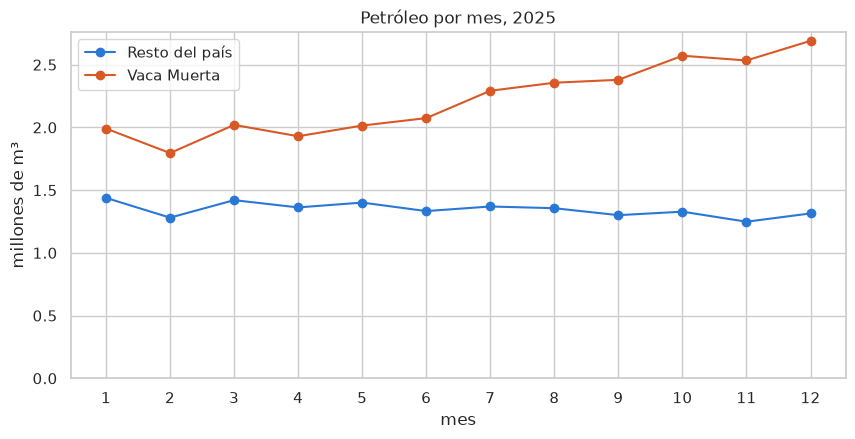

Vaca Muerta, diciembre contra enero: +35%
Resto del país, diciembre contra enero: -9%
Participación de Vaca Muerta: 58 % en enero, 67 % en diciembre


In [4]:
mensual = pet.groupby(["mes", "vaca_muerta"])["prod_pet"].sum().unstack() / 1e6
mensual.columns = ["Resto del país", "Vaca Muerta"]

fig, ax = plt.subplots(figsize=(10, 4.5))
mensual.plot(ax=ax, marker="o", color={"Vaca Muerta": "#d95926", "Resto del país": "#2a78d6"})
ax.set(title="Petróleo por mes, 2025", xlabel="mes", ylabel="millones de m³", ylim=(0, None))
ax.set_xticks(range(1, 13))
plt.show()

cambio = mensual.iloc[-1] / mensual.iloc[0] - 1
participacion = mensual["Vaca Muerta"] / mensual.sum(axis=1) * 100
print(f"Vaca Muerta, diciembre contra enero: {cambio['Vaca Muerta']:+.0%}")
print(f"Resto del país, diciembre contra enero: {cambio['Resto del país']:+.0%}")
print(f"Participación de Vaca Muerta: {participacion.iloc[0]:.0f} % en enero, {participacion.iloc[-1]:.0f} % en diciembre")

Durante 2025 Vaca Muerta creció un **35 %** mientras el resto del país cayó un **9 %**. Su participación pasó del
58 % al 67 % del petróleo en un solo año. El crecimiento del país está explicado por Vaca Muerta; el resto declina,
como es esperable en yacimientos maduros.

### ¿Más pozos o pozos más productivos?

La producción de un mes es, a grandes rasgos, cantidad de pozos × lo que produce cada uno. Separamos los dos
factores: cuántos pozos de Vaca Muerta declararon producción cada mes y cuánto produjo el pozo típico por día
efectivo (la mediana, porque los caudales son muy asimétricos).


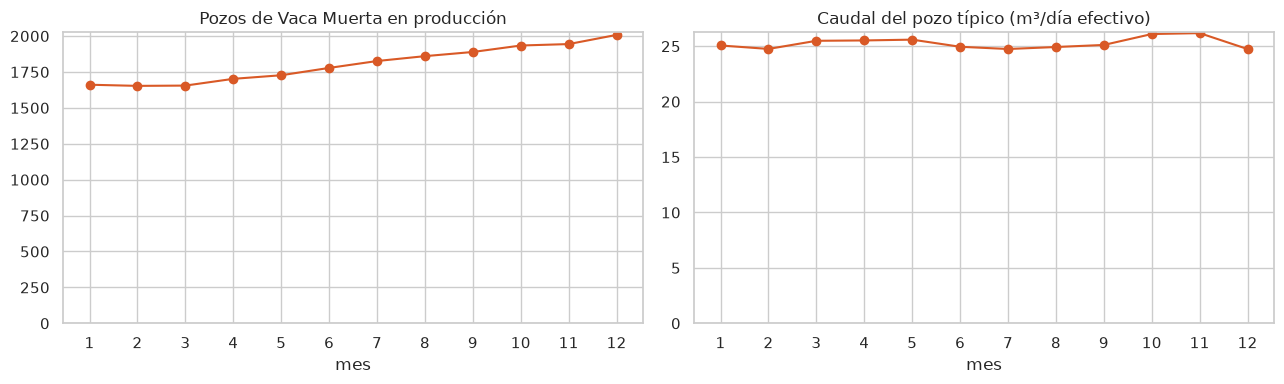

Pozos: 1,661 en enero → 2,008 en diciembre (+21%)
Caudal mediano: entre 24.7 y 26.2 m³/día todo el año


In [5]:
por_mes = vm[vm["tef"] > 0].assign(caudal=lambda x: x["prod_pet"] / x["tef"]).groupby("mes").agg(
    pozos=("idpozo", "nunique"), caudal_mediano=("caudal", "median"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
por_mes["pozos"].plot(ax=axes[0], marker="o", color="#d95926")
axes[0].set(title="Pozos de Vaca Muerta en producción", xlabel="mes", ylim=(0, None))
por_mes["caudal_mediano"].plot(ax=axes[1], marker="o", color="#d95926")
axes[1].set(title="Caudal del pozo típico (m³/día efectivo)", xlabel="mes", ylim=(0, None))
for ax in axes:
    ax.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

print(f"Pozos: {por_mes['pozos'].iloc[0]:,} en enero → {por_mes['pozos'].iloc[-1]:,} en diciembre "
      f"({por_mes['pozos'].iloc[-1] / por_mes['pozos'].iloc[0] - 1:+.0%})")
print(f"Caudal mediano: entre {por_mes['caudal_mediano'].min():.1f} y {por_mes['caudal_mediano'].max():.1f} m³/día todo el año")

**Lectura.** El pozo típico de Vaca Muerta produjo **lo mismo todo el año**, unos 25 m³ por día efectivo. Lo que
cambió fue la **cantidad de pozos**: de 1.661 a 2.008 (+21 %). El crecimiento viene de **perforar más**, no de
pozos más productivos. Que la producción crezca más (+35 %) que los pozos (+21 %) es coherente con esto: los pozos
nuevos de no convencional producen mucho en sus primeros meses, antes de declinar.

## 3. Quién produce en Vaca Muerta


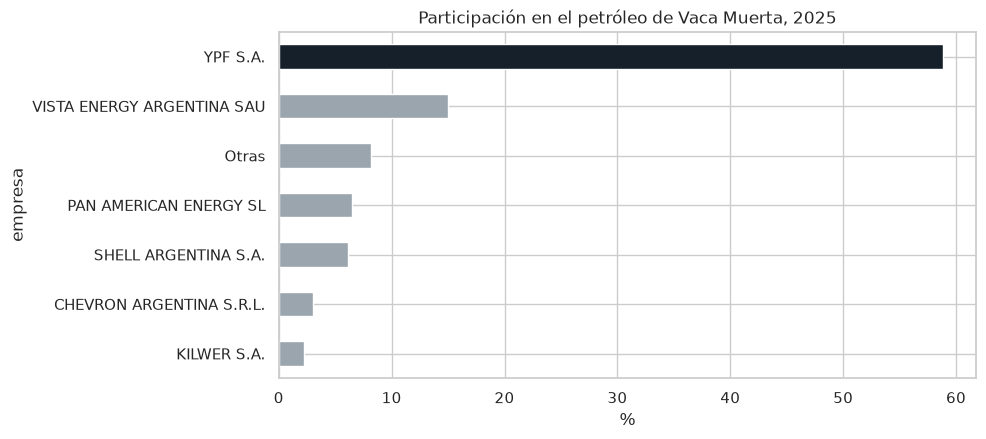

empresa
YPF S.A.                     58.8
VISTA ENERGY ARGENTINA SAU   15.0
PAN AMERICAN ENERGY SL        6.5
SHELL ARGENTINA S.A.          6.2
CHEVRON ARGENTINA S.R.L.      3.0
KILWER S.A.                   2.3
Otras                         8.2
Name: prod_pet, dtype: float64

In [6]:
operadoras = (vm.groupby("empresa")["prod_pet"].sum() / vm["prod_pet"].sum() * 100).sort_values(ascending=False)
top = operadoras.head(6)
top["Otras"] = operadoras.iloc[6:].sum()

fig, ax = plt.subplots(figsize=(9, 4.5))
top.sort_values().plot.barh(ax=ax, color=["#15202B" if e == "YPF S.A." else "#9AA5AE" for e in top.sort_values().index])
ax.set(title="Participación en el petróleo de Vaca Muerta, 2025", xlabel="%")
plt.show()
top

In [7]:
areas = vm.groupby("areayacimiento").agg(
    operadora=("empresa", lambda s: s.value_counts().index[0]),
    petroleo_m3=("prod_pet", "sum"),
).sort_values("petroleo_m3", ascending=False).head(6)
areas["% de Vaca Muerta"] = areas["petroleo_m3"] / vm["prod_pet"].sum() * 100
areas

,operadora,petroleo_m3,% de Vaca Muerta
areayacimiento,,,
LA AMARGA CHICA,YPF S.A.,"4,201,538.0",15.8
LOMA CAMPANA-LLL,YPF S.A.,"3,889,707.7",14.6
BANDURRIA SUR,YPF S.A.,"3,555,126.1",13.3
BAJADA DEL PALO OESTE,VISTA ENERGY ARGENTINA SAU,"2,822,644.2",10.6
LA ANGOSTURA SUR I,YPF S.A.,"1,281,241.8",4.8
LOMA CAMPANA,YPF S.A.,"1,243,759.3",4.7


**YPF opera el 59 % del petróleo de Vaca Muerta**, cuatro veces más que la segunda (Vista). Cinco de las seis
áreas que más produjeron son operadas por YPF: La Amarga Chica, Loma Campana-LLL, Bandurria Sur, La Angostura Sur I y
Loma Campana. La única excepción del podio es Bajada del Palo Oeste, de Vista.

*Operadora* es quien opera el área; muchas áreas tienen socios que no aparecen en este dataset.

## 4. YPF en 2025


YPF produjo el 49% del petróleo del país
El 75% de su petróleo salió de Vaca Muerta


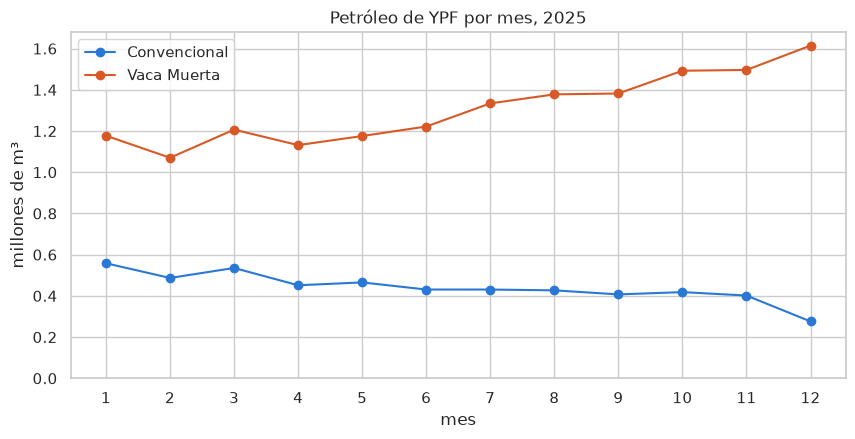

Convencional    -51%
Vaca Muerta     +37%
dtype: str

In [8]:
ypf = pet[pet["es_ypf"]]
print(f"YPF produjo el {ypf['prod_pet'].sum() / total:.0%} del petróleo del país")
print(f"El {ypf.loc[ypf['vaca_muerta'], 'prod_pet'].sum() / ypf['prod_pet'].sum():.0%} de su petróleo salió de Vaca Muerta")

ypf_mes = ypf.groupby(["mes", "vaca_muerta"])["prod_pet"].sum().unstack() / 1e6
ypf_mes.columns = ["Convencional", "Vaca Muerta"]
fig, ax = plt.subplots(figsize=(10, 4.5))
ypf_mes.plot(ax=ax, marker="o", color={"Vaca Muerta": "#d95926", "Convencional": "#2a78d6"})
ax.set(title="Petróleo de YPF por mes, 2025", xlabel="mes", ylabel="millones de m³", ylim=(0, None))
ax.set_xticks(range(1, 13))
plt.show()
(ypf_mes.iloc[-1] / ypf_mes.iloc[0] - 1).map("{:+.0%}".format)

YPF crece un 37 % en Vaca Muerta, pero su petróleo **convencional cae a la mitad**, con un salto brusco en
diciembre. ¿Se agotaron sus pozos convencionales? Antes de concluir, revisamos si esos pozos **siguieron produciendo
con otra operadora**: el dataset identifica cada pozo con `idpozo`, así que podemos seguirlo mes a mes.


In [9]:
conv_ypf = set(pet.loc[pet["es_ypf"] & ~pet["vaca_muerta"], "idpozo"])
historia = pet[pet["idpozo"].isin(conv_ypf) & ~pet["vaca_muerta"]]
cambiaron = historia.groupby("idpozo")["empresa"].nunique().pipe(lambda s: s[s > 1].index)
traspasos = historia[historia["idpozo"].isin(cambiaron) & (historia["empresa"] != "YPF S.A.")]

print(f"{len(cambiaron):,} de {len(conv_ypf):,} pozos convencionales de YPF pasaron a otra operadora en 2025")
primer_mes = traspasos.groupby("idpozo").agg(mes=("mes", "min"), provincia=("provincia", "first"))
pd.crosstab(primer_mes["mes"], primer_mes["provincia"], margins=True, margins_name="Total")

5,636 de 9,735 pozos convencionales de YPF pasaron a otra operadora en 2025


provincia,Chubut,Mendoza,Neuquén,Rio Negro,Santa Cruz,Total
mes,,,,,,
2,166,0,0,5,0,171
4,0,760,0,0,0,760
5,0,1,0,0,0,1
6,0,4,234,0,0,238
7,0,79,10,0,0,89
8,0,37,8,0,0,45
9,0,8,0,0,0,8
12,0,0,0,0,4324,4324
Total,166,889,252,5,4324,5636


In [10]:
traspasos.groupby("empresa")["idpozo"].nunique().sort_values(ascending=False).head(6).rename("pozos recibidos")

empresa
PATAGONIA RESOURCES S.A.         1273
Clear Petroleum S.A.             1251
ROCH S.A.                        1031
PETROLEOS SUDAMERICANOS S.A.      765
QUINTANA E&P ARGENTINA S.R.L.     632
BENTIA ENERGY S.A.                248
Name: pozos recibidos, dtype: int64

**Lectura.** Los pozos no se agotaron: **cambiaron de dueño**. Más de la mitad de los pozos convencionales que YPF
operaba en 2025 pasaron a otras empresas; 4.324 de ellos en diciembre, todos en **Santa Cruz**, y el resto durante
el año en Mendoza, Neuquén y Chubut. Es el reflejo en los datos del **Plan Andes**, el programa con el que YPF se
desprende de sus yacimientos convencionales maduros para concentrarse en Vaca Muerta. Las operadoras que reciben los
pozos (Patagonia Resources, Clear Petroleum, Roch, Petróleos Sudamericanos, Quintana) son las que aparecen como
nuevas operadoras de esas áreas.

Este hallazgo muestra por qué conviene **verificar antes de concluir**: mirando sólo la curva de YPF, la caída
del convencional parecía una declinación de los pozos.

## 5. Conclusiones

- **Vaca Muerta es el motor del petróleo argentino:** con menos del 9 % de los pozos, dio el 62 % del petróleo de
  2025, y su participación subió del 58 % al 67 % en el año.
- **Crece por cantidad de pozos, no por productividad:** el pozo típico produjo unos 25 m³/día todo el año; lo que
  aumentó (+21 %) fue la cantidad de pozos en producción.
- **YPF es el actor central:** produce la mitad del petróleo del país y opera el 59 % del de Vaca Muerta. Tres de
  cada cuatro de sus metros cúbicos ya salen de ahí.
- **YPF se está yendo de lo convencional:** su caída en convencional no es declinación sino traspaso de pozos
  (Plan Andes), que se ve con claridad siguiendo cada pozo en los datos.

**Límites.** Sólo pozos petroleros (el gas de Vaca Muerta queda afuera) y sólo 2025. El traspaso de pozos explica
la caída de YPF, pero no dice nada sobre cómo producirán esos pozos con sus nuevas operadoras: para eso harían falta
datos de 2026.
